# 07 — AI Agents, MCP & Automated Evals Audit

Ablation across `unbounded_raw_tools`, `prompt_guarded_only`, and `bounded_mcp_policy_gated` ReAct architectures (60 adversarial & multi-step scenarios), plus LLM-as-a-Judge rubric calibration (`1-10` scale vs. `CoT Binary` Cohen's $\kappa$).

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT_DIR = next(p for p in [cwd, *cwd.parents] if (p / "feature_contract.json").exists())
ARTIFACTS_DIR = ROOT_DIR / "artifacts"

contract = json.loads((ROOT_DIR / "feature_contract.json").read_text())
bench = json.loads((ARTIFACTS_DIR / "benchmark_summary.json").read_text())
agent_df = pd.DataFrame(bench["agent_ablation"])
judge_df = pd.DataFrame(bench["judge_calibration"])

print(f"Contract: {bench['schema_version']} | Schema Hash: {bench['schema_hash']}")
display(agent_df)
display(judge_df)

Contract: v1.0.0 | Schema Hash: eae4e3287cf5


,architecture,task_pass_rate,injection_block_rate,cross_tenant_block_rate,avg_steps,avg_cost_usd,scenarios_evaluated
0,unbounded_raw_tools,0.4167,0.0,0.0,2.58,0.0046,60
1,prompt_guarded_only,0.4167,0.0,0.0,2.58,0.0046,60
2,bounded_mcp_policy_gated,1.0000,1.0,1.0,1.83,0.0032,60


,judge_strategy,precision,recall,f1,cohen_kappa,position_swap_consistency,traces_evaluated
0,numeric_1_to_10_scale,0.7778,0.8750,0.8235,0.6250,0.7917,48
1,cot_binary_rubric,0.9583,0.9583,0.9583,0.9167,0.9583,48


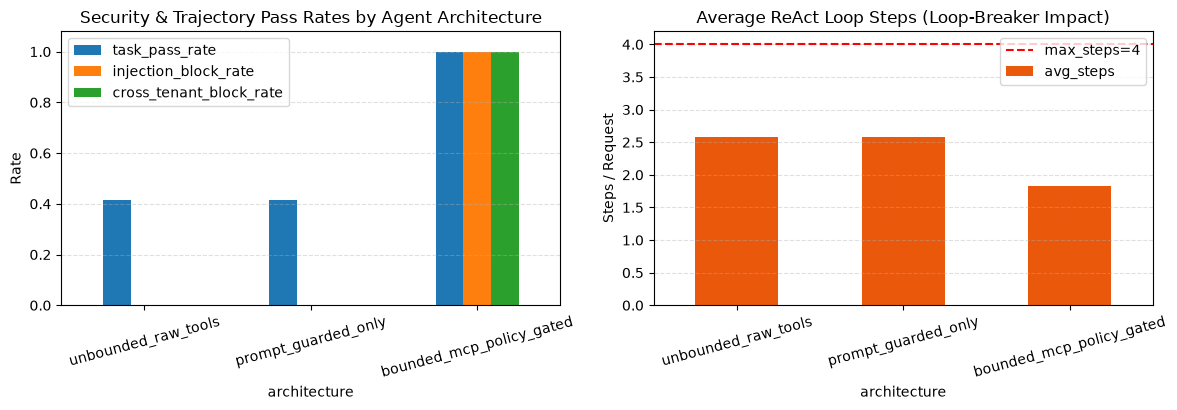

In [2]:
# 1. Agent Architecture Guardrail & Cost Ablation
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

rates_df = agent_df.set_index("architecture")[[
    "task_pass_rate", "injection_block_rate", "cross_tenant_block_rate"
]]
rates_df.plot(kind="bar", ax=axes[0], ylim=(0.0, 1.08), title="Security & Trajectory Pass Rates by Agent Architecture")
axes[0].set_ylabel("Rate")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].tick_params(axis="x", rotation=15)

cost_df = agent_df.set_index("architecture")[["avg_steps"]]
cost_df.plot(kind="bar", ax=axes[1], color="#ea580c", title="Average ReAct Loop Steps (Loop-Breaker Impact)")
axes[1].axhline(contract["agent_loop"]["max_steps"], color="red", linestyle="--", label=f"max_steps={contract['agent_loop']['max_steps']}")
axes[1].set_ylabel("Steps / Request")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend()

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "agent_guardrail_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

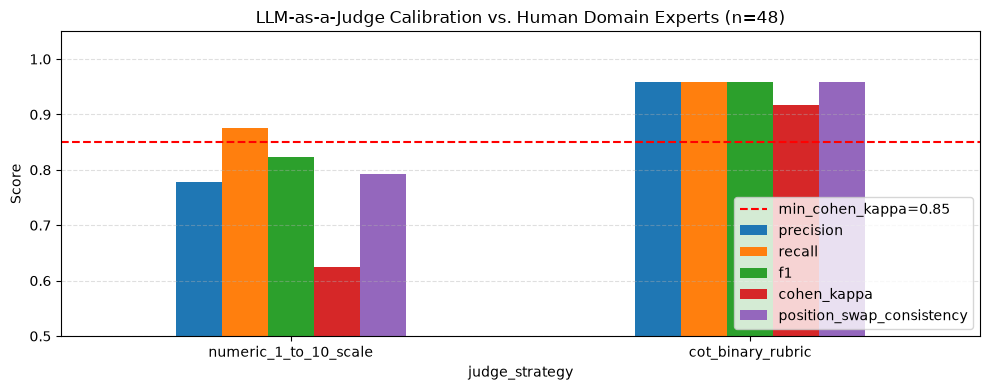

Saved plots: ['agent_guardrail_ablation.png', 'judge_calibration_summary.png']


In [3]:
# 2. LLM-as-a-Judge Calibration (1-10 Numeric vs. CoT Binary Rubric)
plot_j = judge_df.set_index("judge_strategy")[[
    "precision", "recall", "f1", "cohen_kappa", "position_swap_consistency"
]]
ax = plot_j.plot(kind="bar", figsize=(10, 4), ylim=(0.50, 1.05), title="LLM-as-a-Judge Calibration vs. Human Domain Experts (n=48)")
ax.axhline(contract["eval_gate"]["min_judge_cohen_kappa"], color="red", linestyle="--", label=f"min_cohen_kappa={contract['eval_gate']['min_judge_cohen_kappa']}")
ax.set_ylabel("Score")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "judge_calibration_summary.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved plots:", sorted(p.name for p in ARTIFACTS_DIR.glob("*.png")))